<a href="https://colab.research.google.com/github/abd500253-coder/Machine_Learning_Journey/blob/main/Support_Vector_Machine_Practice/Support_Vector_Machine_Practice.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### Breast Cancer Dataset Classification (Linear SVM)

* **Purpose:** Loads the `load_breast_cancer` dataset, standardizes features, and trains a basic `SVC` classifier to evaluate performance.
* **Key Steps:**
* Imports necessary libraries (`train_test_split`, `StandardScaler`, `classification_report`, `SVC`).
* Splits the dataset into 80% training and 20% testing sets.
* Standardizes the feature scales to optimize SVM performance.
* Trains a default Support Vector Classifier and prints out the classification report (achieving ~98% accuracy).



In [14]:
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report
# TODO: Import the correct SVM module
from sklearn.svm import SVC
# 1. Load and prepare data
data = load_breast_cancer()
X, y = data.data, data.target

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 2. Scale features (Crucial for SVM performance)
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# ==========================================
# YOUR TASK:
# 1. Instantiate the SVM classifier.
# 2. Train (fit) it on the training data.
# ==========================================

model = SVC()
model.fit(X_train, y_train)
# model = ...
# model.fit(...)

# 3. Evaluate your model
# predictions = model.predict(X_test)
# print(classification_report(y_test, predictions))

y_pred = model.predict(X_test)
print(classification_report(y_test, y_pred))


              precision    recall  f1-score   support

           0       1.00      0.95      0.98        43
           1       0.97      1.00      0.99        71

    accuracy                           0.98       114
   macro avg       0.99      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114




### Non-Linear Data (Make Moons) & Kernel Comparison

* **Purpose:** Demonstrates the limitation of linear boundaries and the power of kernel tricks using the `make_moons` dataset.
* **Key Steps:**
* Generates non-linear moon-shaped data samples with noise.
* Compares a **Linear Kernel** (`kernel='linear'`) against a **Radial Basis Function (RBF) Kernel** (`kernel='rbf'`).
* Evaluates both models, showing that the RBF kernel handles non-linear boundaries significantly better (~99% vs. ~90% accuracy).

In [15]:
import matplotlib.pyplot as plt
from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

# 1. Generate non-linear moon-shaped data
X, y = make_moons(n_samples=300, noise=0.15, random_state=42)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# ==========================================
# YOUR TASK:
# Try creating two different models to see how they perform:
# Model A: Use kernel='linear'
# Model B: Use kernel='rbf' (Radial Basis Function)
# ==========================================
model_linear = SVC(kernel='linear')
model_linear.fit(X_train, y_train)
y_pred_linear = model_linear.predict(X_test)
print("Classification report of Linear model\n")
print(classification_report(y_test, y_pred_linear))
print('-'*50)


model_rbf = SVC(kernel='rbf')
model_rbf.fit(X_train, y_train)
y_pred_rbf = model_rbf.predict(X_test)
print("Classification report of RBF model\n")
print(classification_report(y_test, y_pred_rbf))
# model_linear = ...
# model_rbf = ...


Classification report of Linear model

              precision    recall  f1-score   support

           0       0.89      0.87      0.88        38
           1       0.91      0.92      0.91        52

    accuracy                           0.90        90
   macro avg       0.90      0.90      0.90        90
weighted avg       0.90      0.90      0.90        90

--------------------------------------------------
Classification report of RBF model

              precision    recall  f1-score   support

           0       0.97      1.00      0.99        38
           1       1.00      0.98      0.99        52

    accuracy                           0.99        90
   macro avg       0.99      0.99      0.99        90
weighted avg       0.99      0.99      0.99        90




### Decision Boundary Visualization Helper Function

* **Purpose:** Defines a reusable utility function (`plot_decision_boundary`) to visualize how classifiers separate data points across a meshgrid.
* **Key Steps:**
* Computes minimum and maximum values for features to build a coordinate grid.
* Uses model predictions across the grid to render contour decision boundaries (`plt.contourf`).
* Overlays scatter plots of actual data points to visually demonstrate the learned decision surface.


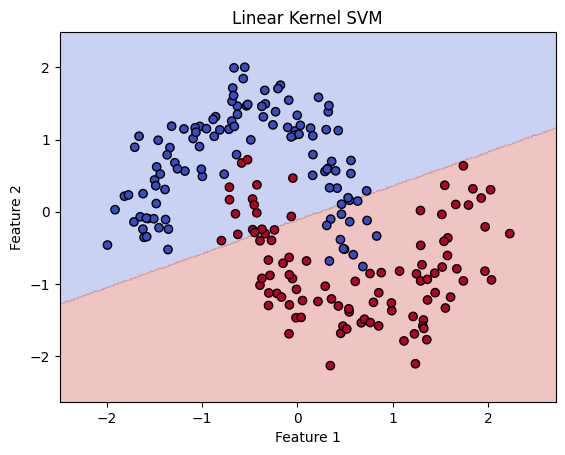

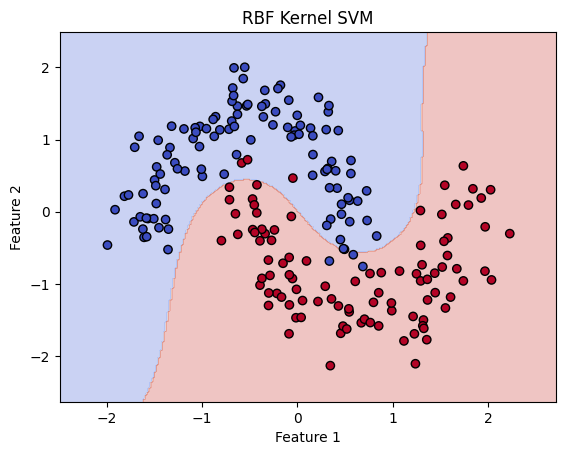

In [16]:
import numpy as np

def plot_decision_boundary(model, X, y, title):
    # Set up min and max values for the meshgrid
    x_min, x_max = X[:, 0].min() - 0.5, X[:, 0].max() + 0.5
    y_min, y_max = X[:, 1].min() - 0.5, X[:, 1].max() + 0.5
    xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.02),
                         np.arange(y_min, y_max, 0.02))

    # Predict values for the entire grid
    Z = model.predict(np.c_[xx.ravel(), yy.ravel()])
    Z = Z.reshape(xx.shape)

    # Plot the contour boundary and data points
    plt.contourf(xx, yy, Z, alpha=0.3, cmap=plt.cm.coolwarm)
    plt.scatter(X[:, 0], X[:, 1], c=y, edgecolors='k', cmap=plt.cm.coolwarm)
    plt.title(title)
    plt.xlabel('Feature 1')
    plt.ylabel('Feature 2')
    plt.show()

# Run these after you fit your models:
plot_decision_boundary(model_linear, X_train, y_train, "Linear Kernel SVM")
plot_decision_boundary(model_rbf, X_train, y_train, "RBF Kernel SVM")



### Hyperparameter Tuning with GridSearchCV

* **Purpose:** Performs automated hyperparameter optimization on the `load_digits` dataset using 5-fold cross-validation.
* **Key Steps:**
* Defines a parameter grid testing different values for regularization (`C`), kernel coefficient (`gamma`), and kernel type.
* Uses `GridSearchCV` to exhaustively search for the best configuration (`C: 100`, `gamma: 0.01`, `kernel: 'rbf'`).
* Evaluates the best resulting estimator on the test dataset, yielding a robust 98% classification report across 10 handwritten digit classes.

In [17]:
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import classification_report

# 1. Load handwritten digits dataset (8x8 pixel images of digits 0-9)
digits = load_digits()
X, y = digits.data, digits.target
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 2. Scale features
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# ==========================================
# SOLUTION CODE
# ==========================================

# Step 1: Define a dictionary of hyperparameters to test
# 'C' decides the margin penalty, 'gamma' decides how tight the curve wraps
param_grid = {
    'C': [0.1, 1, 10, 100],
    'gamma': [0.001, 0.01, 0.1, 'scale'],
    'kernel': ['rbf', 'linear']
}

# Step 2: Initialize GridSearchCV
# We pass the base estimator (SVC), our grid parameters, and use 5-Fold cross-validation
# n_jobs=-1 forces the system to use all your computer's processors to run faster
grid_search = GridSearchCV(estimator=SVC(), param_grid=param_grid, cv=5, n_jobs=-1, verbose=1)

# Step 3: Run the grid sweep on our training data
grid_search.fit(X_train, y_train)

# Step 4: Extract and view the optimal settings found by the sweep
print("\n" + "="*40)
print("BEST HYPERPARAMETERS FOUND:", grid_search.best_params_)
print(f"BEST TRAINING CROSS-VALIDATION SCORE: {grid_search.best_score_ * 100:.2f}%")
print("="*40 + "\n")

# Step 5: Test this optimized model configuration on hidden test data
best_model = grid_search.best_estimator_
y_pred = best_model.predict(X_test)

print("Classification Report on Test Data using Best Configuration:")
print(classification_report(y_test, y_pred))


Fitting 5 folds for each of 32 candidates, totalling 160 fits

BEST HYPERPARAMETERS FOUND: {'C': 100, 'gamma': 0.01, 'kernel': 'rbf'}
BEST TRAINING CROSS-VALIDATION SCORE: 98.12%

Classification Report on Test Data using Best Configuration:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        33
           1       1.00      1.00      1.00        28
           2       0.97      1.00      0.99        33
           3       0.97      0.97      0.97        34
           4       1.00      1.00      1.00        46
           5       0.98      0.96      0.97        47
           6       0.97      1.00      0.99        35
           7       1.00      0.97      0.99        34
           8       0.97      0.97      0.97        30
           9       0.95      0.95      0.95        40

    accuracy                           0.98       360
   macro avg       0.98      0.98      0.98       360
weighted avg       0.98      0.98      0.98       360

